In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from PIL import Image
import os

data_dir = './data'

img_col = 'image_ID'
label_col = 'label'

train_df = pd.read_csv(f'{data_dir}/train.csv')
test_df = pd.read_csv(f'{data_dir}/test.csv')

train_df['filepath'] = train_df[img_col].apply(lambda x: f'{data_dir}/train/{x}')
test_df['filepath'] = test_df[img_col].apply(lambda x: f'{data_dir}/test/{x}')

print(train_df.shape, test_df.shape)
print(train_df.columns.tolist())
assert 'filepath' in train_df.columns, "filepath column missing — rerun this cell"
print("First filepath exists:", os.path.exists(train_df['filepath'].iloc[0]))
train_df.head()

(8227, 3) (2056, 2)
['image_ID', 'label', 'filepath']
First filepath exists: True


,image_ID,label,filepath
0,7c225f7b61.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
1,b31.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
2,acb146546c.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
3,0e62f4d8f2.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
4,cfd2c28c74.jpg,Cricket,/kaggle/input/datasets/sidharkal/sports-image-...


In [2]:
img_col = 'image_ID'
label_col = 'label'

train_df['filepath'] = train_df[img_col].apply(lambda x: f'{data_dir}/train/{x}')
test_df['filepath'] = test_df[img_col].apply(lambda x: f'{data_dir}/test/{x}')

train_df.head()

,image_ID,label,filepath
0,7c225f7b61.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
1,b31.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
2,acb146546c.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
3,0e62f4d8f2.jpg,Badminton,/kaggle/input/datasets/sidharkal/sports-image-...
4,cfd2c28c74.jpg,Cricket,/kaggle/input/datasets/sidharkal/sports-image-...


In [4]:
print("Number of classes:", train_df[label_col].nunique())
print(train_df[label_col].value_counts())

Number of classes: 7
label
Cricket      1556
Wrestling    1471
Tennis       1445
Badminton    1394
Soccer       1188
Swimming      595
Karate        578
Name: count, dtype: int64


Number of classes: 7


/tmp/ipykernel_58/2750895161.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=train_df[label_col], order=order, palette='viridis')


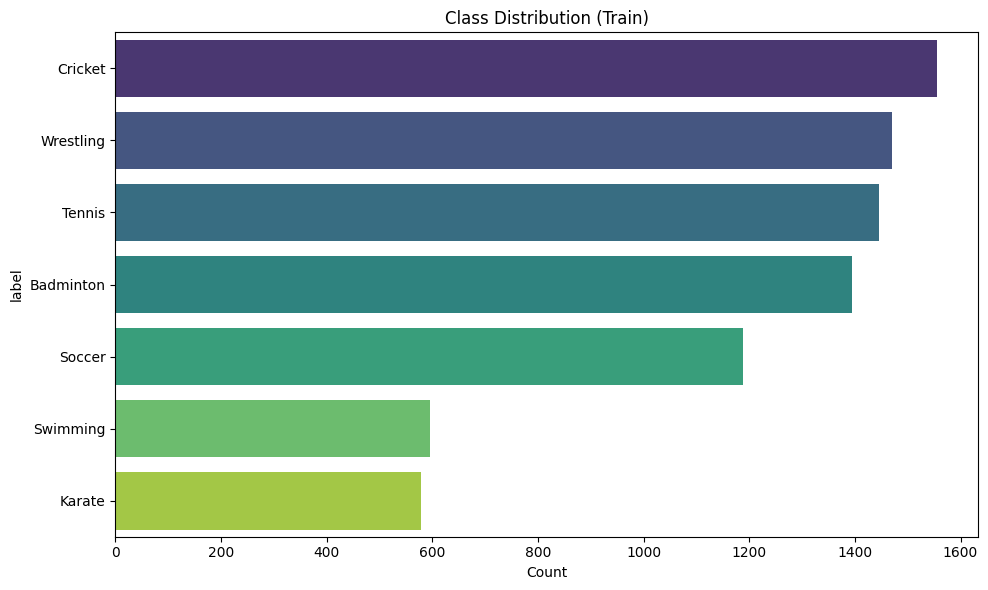

Most common: Cricket (1556)
Least common: Karate (578)
Imbalance ratio (max/min): 2.69


In [5]:
class_names = sorted(train_df[label_col].unique())
print(f"Number of classes: {len(class_names)}")

plt.figure(figsize=(10, 6))
order = train_df[label_col].value_counts().index
sns.countplot(y=train_df[label_col], order=order, palette='viridis')
plt.title('Class Distribution (Train)')
plt.xlabel('Count')
plt.tight_layout()
plt.show()

counts = train_df[label_col].value_counts()
print(f"Most common: {counts.idxmax()} ({counts.max()})")
print(f"Least common: {counts.idxmin()} ({counts.min()})")
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")

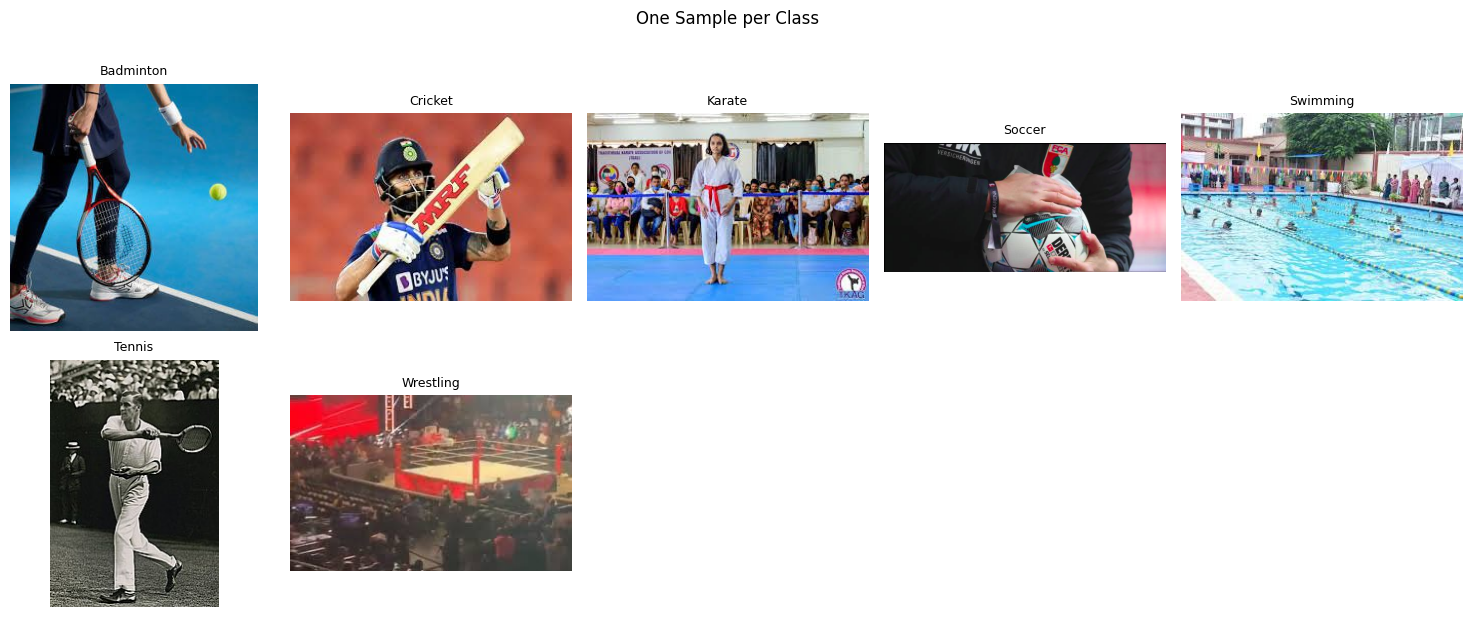

In [6]:
n_classes = len(class_names)
cols = 5
rows = int(np.ceil(n_classes / cols))

plt.figure(figsize=(cols * 3, rows * 3))
for i, cls in enumerate(class_names):
    row = train_df[train_df[label_col] == cls].sample(1, random_state=1).iloc[0]
    img = Image.open(row['filepath'])
    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(cls, fontsize=9)
    plt.axis('off')
plt.suptitle('One Sample per Class', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
train_split, val_split = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df[label_col]
)

print("Train:", train_split.shape, "Val:", val_split.shape)

Train: (6581, 3) Val: (1646, 3)


In [8]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_split,
    x_col='filepath',
    y_col=label_col,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_split,
    x_col='filepath',
    y_col=label_col,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)
idx_to_class = {v: k for k, v in train_generator.class_indices.items()}
print("Classes:", train_generator.class_indices)

Found 6581 validated image filenames belonging to 7 classes.
Found 1646 validated image filenames belonging to 7 classes.
Classes: {'Badminton': 0, 'Cricket': 1, 'Karate': 2, 'Soccer': 3, 'Swimming': 4, 'Tennis': 5, 'Wrestling': 6}


In [9]:
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax')
])
 
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

I0000 00:00:1787711390.571868      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787711390.574805      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,426 (16.73 MB)

 Trainable params: 332,295 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [10]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor='val_accuracy'),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, monitor='val_loss', min_lr=1e-7)
]

epochs = 30

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    callbacks=callbacks
)

Epoch 1/30


2026-08-26 02:30:19.113207: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:30:19.256708: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:30:19.607757: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:30:19.748892: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:30:20.553337: E external/local_xla/xla/stream_

158/206 ━━━━━━━━━━━━━━━━━━━━ 32s 681ms/step - accuracy: 0.7027 - loss: 0.9310

2026-08-26 02:32:23.363427: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:32:23.505337: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:32:23.859269: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:32:24.001804: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:32:24.143616: E external/local_xla/xla/stream_

206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 756ms/step - accuracy: 0.7296 - loss: 0.8470

2026-08-26 02:33:35.216299: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:33:35.355802: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:33:35.677324: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:33:35.818470: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 02:33:36.611306: E external/local_xla/xla/stream_

206/206 ━━━━━━━━━━━━━━━━━━━━ 222s 939ms/step - accuracy: 0.8233 - loss: 0.5510 - val_accuracy: 0.9484 - val_loss: 0.1744 - learning_rate: 0.0010
Epoch 2/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 100s 484ms/step - accuracy: 0.9079 - loss: 0.2860 - val_accuracy: 0.9514 - val_loss: 0.1484 - learning_rate: 0.0010
Epoch 3/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 99s 483ms/step - accuracy: 0.9272 - loss: 0.2091 - val_accuracy: 0.9611 - val_loss: 0.1282 - learning_rate: 0.0010
Epoch 4/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 99s 482ms/step - accuracy: 0.9363 - loss: 0.1790 - val_accuracy: 0.9575 - val_loss: 0.1283 - learning_rate: 0.0010
Epoch 5/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 98s 478ms/step - accuracy: 0.9527 - loss: 0.1472 - val_accuracy: 0.9563 - val_loss: 0.1370 - learning_rate: 0.0010
Epoch 6/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 99s 478ms/step - accuracy: 0.9523 - loss: 0.1394 - val_accuracy: 0.9538 - val_loss: 0.1378 - learning_rate: 0.0010
Epoch 7/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 99s 479ms/step - accuracy: 0.9550 - los

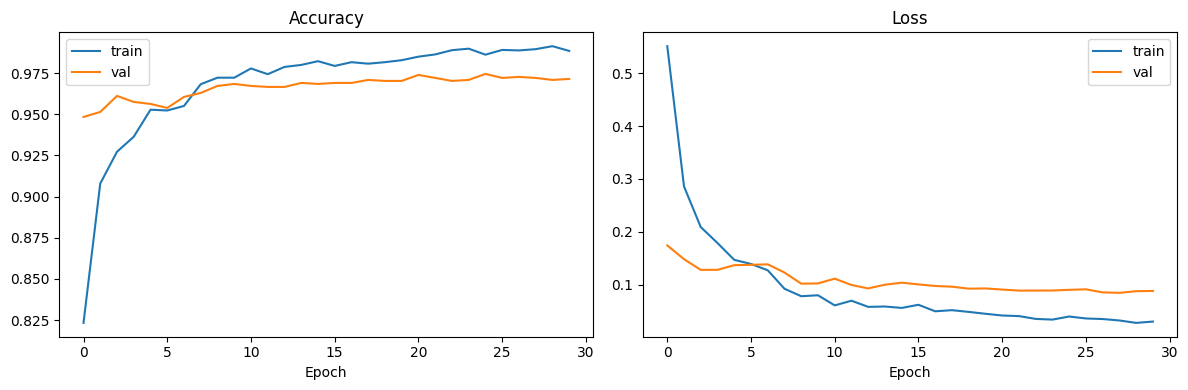

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='val')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='val')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

Validation accuracy: 0.9745
              precision    recall  f1-score   support

   Badminton       0.96      0.97      0.97       279
     Cricket       0.98      0.98      0.98       311
      Karate       0.97      0.99      0.98       116
      Soccer       0.98      0.99      0.99       238
    Swimming       1.00      0.97      0.99       119
      Tennis       0.95      0.96      0.96       289
   Wrestling       0.99      0.97      0.98       294

    accuracy                           0.97      1646
   macro avg       0.98      0.98      0.98      1646
weighted avg       0.97      0.97      0.97      1646



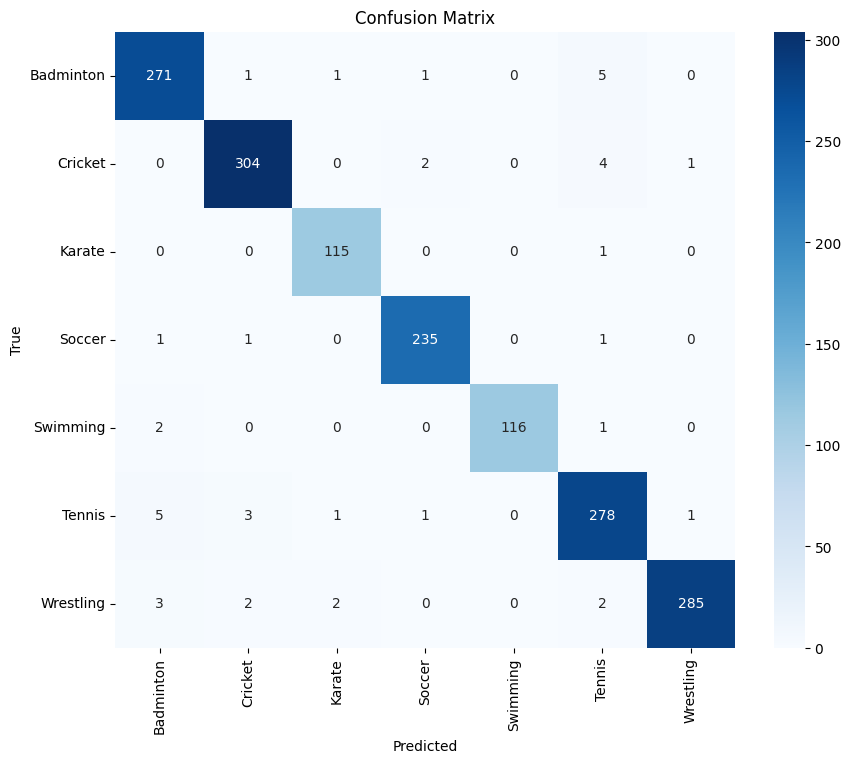

In [12]:
val_loss, val_acc = model.evaluate(val_generator, verbose=0)
print(f"Validation accuracy: {val_acc:.4f}")

from sklearn.metrics import classification_report, confusion_matrix

val_generator.reset()
preds = model.predict(val_generator, verbose=0)
y_pred = np.argmax(preds, axis=1)
y_true = val_generator.classes
class_labels = list(train_generator.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_labels))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

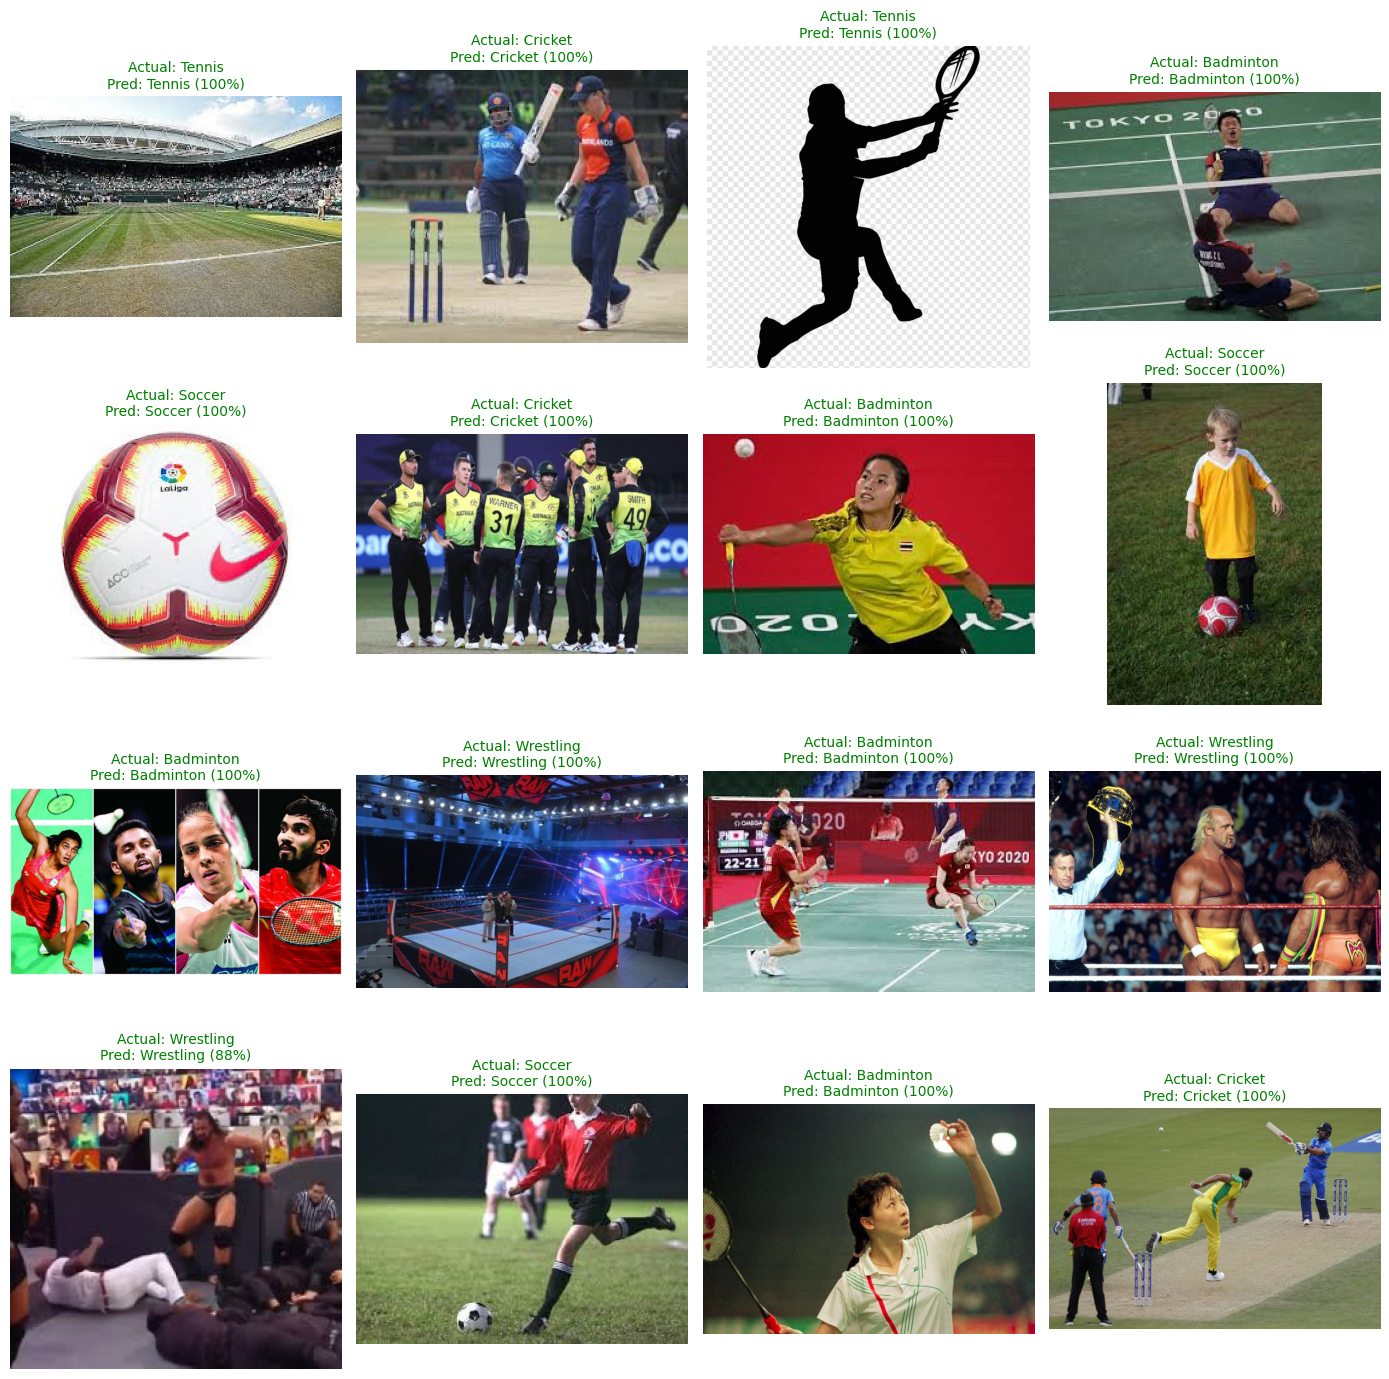

In [15]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

val_split = val_split.reset_index(drop=True)

np.random.seed(7)
sample_idx = np.random.choice(len(val_split), 16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for ax, i in zip(axes, sample_idx):
    filepath = val_split.iloc[i]['filepath']
    actual = class_labels[y_true[i]]
    pred = class_labels[y_pred[i]]
    confidence = y_pred_probs_full[i][y_pred[i]]
    color = "green" if y_true[i] == y_pred[i] else "red"

    img = Image.open(filepath)
    ax.imshow(img)
    ax.set_title(f"Actual: {actual}\nPred: {pred} ({confidence:.0%})", color=color, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

Total misclassified: 42 / 1646


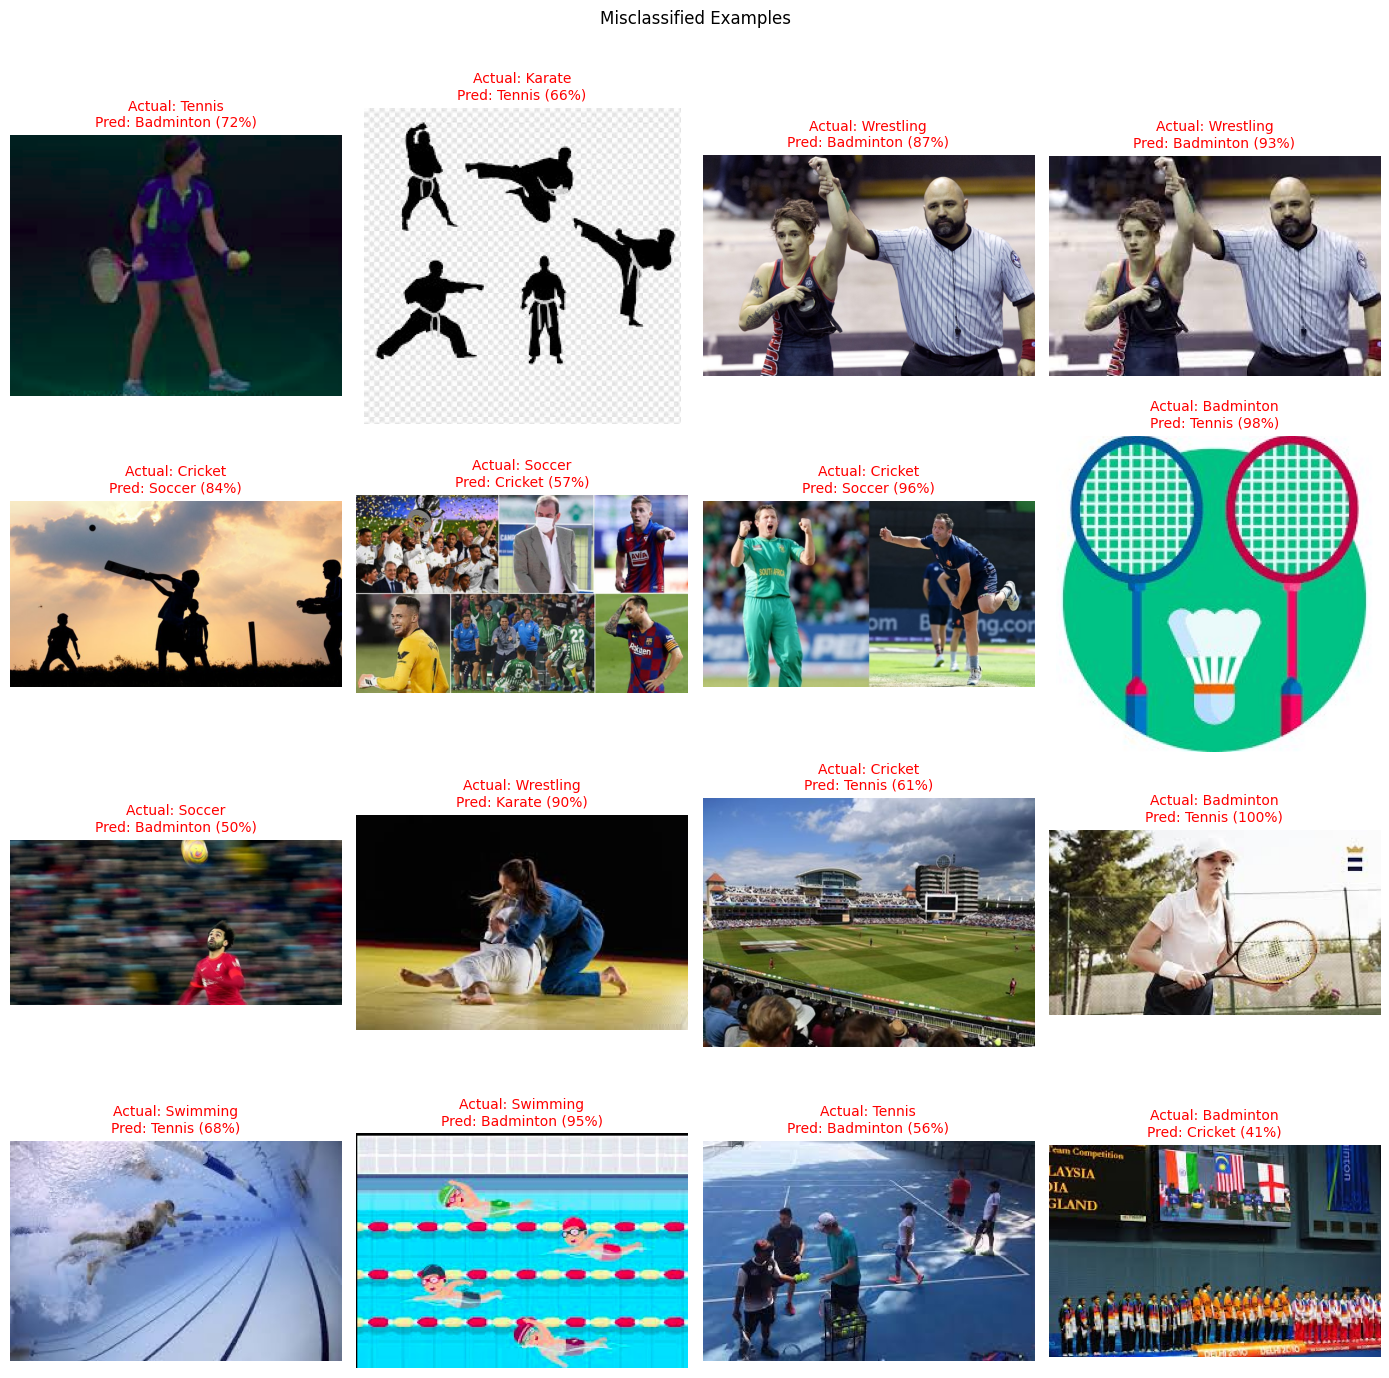

In [16]:
misclassified_idx = np.where(y_true != y_pred)[0]
print(f"Total misclassified: {len(misclassified_idx)} / {len(y_true)}")

sample_idx = np.random.choice(misclassified_idx, min(16, len(misclassified_idx)), replace=False)

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for ax, i in zip(axes, sample_idx):
    filepath = val_split.iloc[i]['filepath']
    actual = class_labels[y_true[i]]
    pred = class_labels[y_pred[i]]
    confidence = y_pred_probs_full[i][y_pred[i]]

    img = Image.open(filepath)
    ax.imshow(img)
    ax.set_title(f"Actual: {actual}\nPred: {pred} ({confidence:.0%})", color="red", fontsize=10)
    ax.axis("off")

plt.suptitle("Misclassified Examples", y=1.01)
plt.tight_layout()
plt.show()